In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
data40 = pd.read_csv("ABP_B_data40.csv", skiprows=3, skipinitialspace=True)
data65 = pd.read_csv("ABP_B_data65.csv", skiprows=3, skipinitialspace=True)
data90 = pd.read_csv("ABP_B_data90.csv", skiprows=3, skipinitialspace=True)

for data in [data40, data65, data90]: data.columns = data.columns.str.strip()

data40 = data40.iloc[1:].reset_index(drop=True)
data65 = data65.iloc[1:].reset_index(drop=True)
data90 = data90.iloc[1:].reset_index(drop=True)
data40 = data40.apply(pd.to_numeric)
data65 = data65.apply(pd.to_numeric)
data90 = data90.apply(pd.to_numeric)

Saving ABP_B_data65.csv to ABP_B_data65.csv
Saving ABP_B_data90.csv to ABP_B_data90.csv
Saving ABP_B_data40.csv to ABP_B_data40.csv


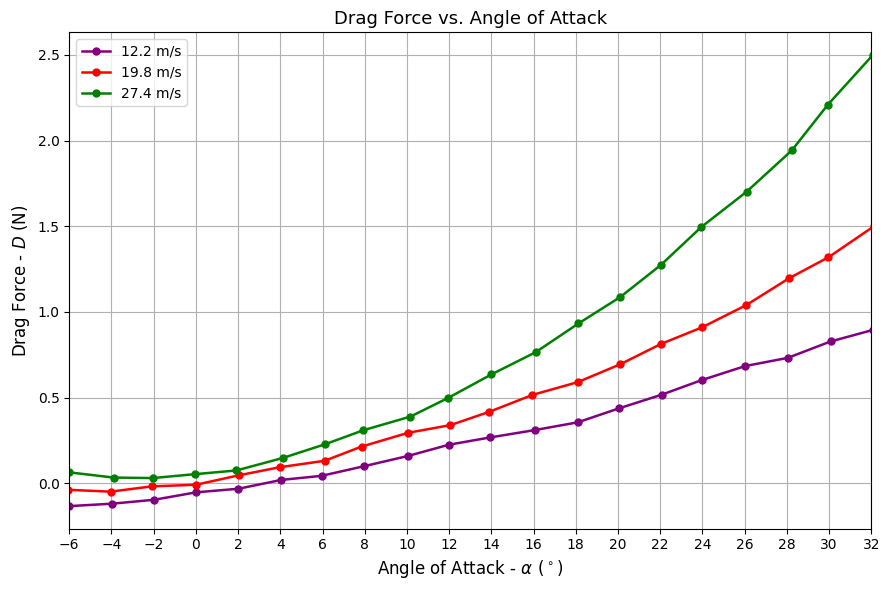

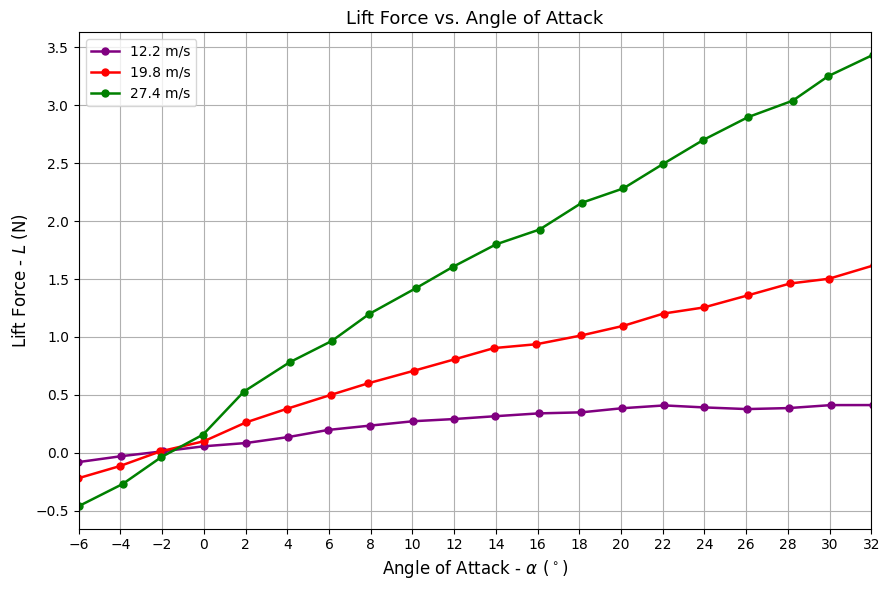

In [12]:
def process_data(data):
    alpha = data['Angle of Attack'].to_numpy()
    q = data['Corrected q'].to_numpy() #[dpsi]
    velocity_ft_s = data['Avg Velocity'].to_numpy()

    axial_recorded = data['Axial Force'].to_numpy() #[lbf]
    normal_recorded = data['Normal Force'].to_numpy() #[lbf]
    moment_recorded = data['Pitching Mom'].to_numpy() #[in-lbf]

    velocity_ms = velocity_ft_s * 0.3048
    alpha_rad = np.deg2rad(alpha)

    mass_kg = 26.63/1000 #[kg]
    g = 9.81 #[m/s^2]

    weight_N = mass_kg*g
    weight_lbf = weight_N/4.44822

    # tare angle
    alpha_tare = np.deg2rad(-6.0)

    # correct axial and normal forces
    axial = (axial_recorded - weight_lbf * (np.sin(alpha_rad) - np.sin(alpha_tare)))
    normal = (normal_recorded + weight_lbf * (np.cos(alpha_rad) - np.cos(alpha_tare)))

    drag_lbf = (axial * np.cos(alpha_rad)) + (normal * np.sin(alpha_rad))
    lift_lbf = (normal * np.cos(alpha_rad)) - (axial * np.sin(alpha_rad))

    # convert forces to newtons
    drag_N = drag_lbf * 4.44822
    lift_N = lift_lbf * 4.44822

    return (alpha, q, velocity_ms, axial, normal, moment_recorded, drag_lbf, lift_lbf, drag_N, lift_N)

alpha40, q40, V40, A40, N40, M40, D40, L40, D40_N, L40_N = process_data(data40)
alpha65, q65, V65, A65, N65, M65, D65, L65, D65_N, L65_N = process_data(data65)
alpha90, q90, V90, A90, N90, M90, D90, L90, D90_N, L90_N = process_data(data90)


plt.figure(figsize=(9, 6))
plt.plot(alpha40, D40_N, color='purple', marker='o', linewidth=1.8, markersize=5, label='12.2 m/s')
plt.plot(alpha65, D65_N, color='red', marker='o', linewidth=1.8, markersize=5, label='19.8 m/s')
plt.plot(alpha90, D90_N, color='green', marker='o', linewidth=1.8, markersize=5, label='27.4 m/s')
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'Drag Force - $D$ (N)', fontsize=12)
plt.title('Drag Force vs. Angle of Attack', fontsize=13)
plt.xlim(-6, 32)
plt.xticks(np.arange(-6, 33, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
plt.plot(alpha40, L40_N, color='purple', marker='o', linewidth=1.8, markersize=5, label='12.2 m/s')
plt.plot(alpha65, L65_N, color='red', marker='o', linewidth=1.8, markersize=5, label='19.8 m/s')
plt.plot(alpha90, L90_N, color='green', marker='o', linewidth=1.8, markersize=5, label='27.4 m/s')
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'Lift Force - $L$ (N)', fontsize=12)
plt.title('Lift Force vs. Angle of Attack', fontsize=13)
plt.xlim(-6, 32)
plt.xticks(np.arange(-6, 33, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

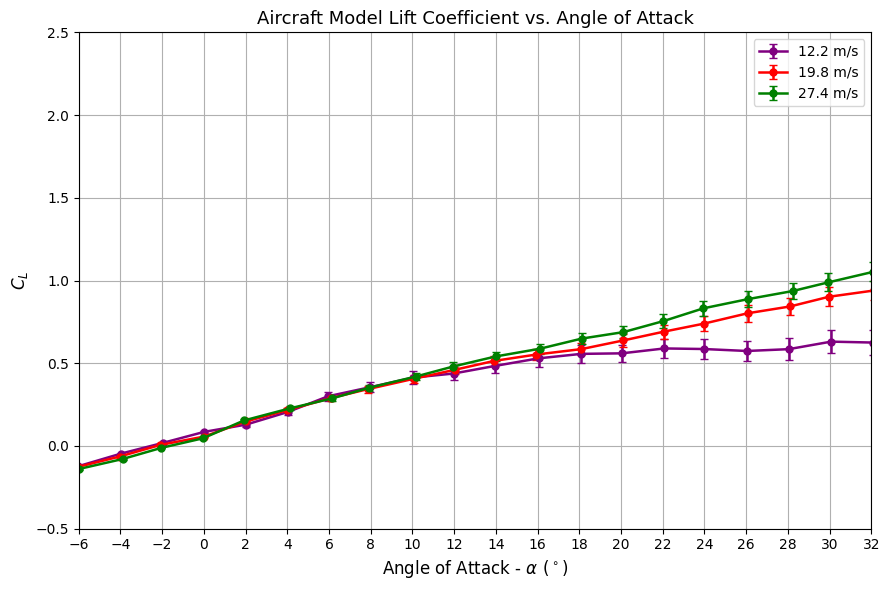

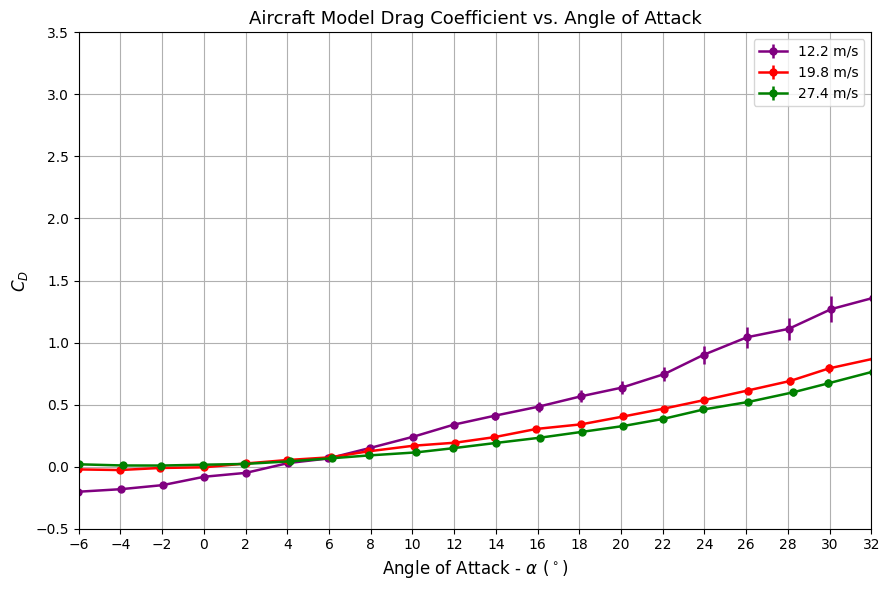

In [42]:
S_ft2 = 0.0819027778 #[ft^2]

# dynamic pressure from psi to psf
q40_psf = q40 * 144
q65_psf = q65 * 144
q90_psf = q90 * 144

# lift coefficients
CL40 = L40 / (q40_psf * S_ft2)
CL65 = L65 / (q65_psf * S_ft2)
CL90 = L90 / (q90_psf * S_ft2)

# drag coefficients
CD40 = D40 / (q40_psf * S_ft2)
CD65 = D65 / (q65_psf * S_ft2)
CD90 = D90 / (q90_psf * S_ft2)

# balance uncertainty
U_BAL = 0.05

# aoa uncertainty
U_ALPHA = np.deg2rad(0.2)

# omega PX653 uncertainty
U_q_psi = 0.000903

# psi to psf
U_q_psf = U_q_psi * 144

U_A40 = U_BAL * np.abs(A40)
U_A65 = U_BAL * np.abs(A65)
U_A90 = U_BAL * np.abs(A90)

U_N40 = U_BAL * np.abs(N40)
U_N65 = U_BAL * np.abs(N65)
U_N90 = U_BAL * np.abs(N90)

def force_uncertainty(alpha, A, N, U_A, U_N, U_ALPHA):
    a = np.deg2rad(alpha)
    U_L = np.sqrt((np.cos(a) * U_N)**2 + (np.sin(a) * U_A)**2 + ((N * np.sin(a) + A * np.cos(a)) * U_ALPHA)**2)
    U_D = np.sqrt((np.sin(a) * U_N)**2 + (np.cos(a) * U_A)**2 + ((N * np.cos(a) - A * np.sin(a)) * U_ALPHA)**2)
    return U_L, U_D

U_L40, U_D40 = force_uncertainty(alpha40, A40, N40, U_A40, U_N40, U_ALPHA)
U_L65, U_D65 = force_uncertainty(alpha65, A65, N65, U_A65, U_N65, U_ALPHA)
U_L90, U_D90 = force_uncertainty(alpha90, A90, N90, U_A90, U_N90, U_ALPHA)

def coefficient_uncertainty(force, U_force, q_psf, U_q_psf, S_ft2):
    return np.sqrt((U_force / (q_psf * S_ft2))**2 + (force * U_q_psf / (q_psf**2 * S_ft2))**2)

U_CL40 = coefficient_uncertainty(L40, U_L40, q40_psf, U_q_psf, S_ft2)
U_CL65 = coefficient_uncertainty(L65, U_L65, q65_psf, U_q_psf, S_ft2)
U_CL90 = coefficient_uncertainty(L90, U_L90, q90_psf, U_q_psf, S_ft2)

U_CD40 = coefficient_uncertainty(D40, U_D40, q40_psf, U_q_psf, S_ft2)
U_CD65 = coefficient_uncertainty(D65, U_D65, q65_psf, U_q_psf, S_ft2)
U_CD90 = coefficient_uncertainty(D90, U_D90, q90_psf, U_q_psf, S_ft2)

plt.figure(figsize=(9, 6))
plt.errorbar(alpha40, CL40, yerr=U_CL40, color='purple', marker='o', linewidth=1.8, markersize=5, capsize=3,label='12.2 m/s')
plt.errorbar(alpha65, CL65, yerr=U_CL65, color='red', marker='o', linewidth=1.8, markersize=5, capsize=3, label='19.8 m/s')
plt.errorbar(alpha90, CL90, yerr=U_CL90, color='green', marker='o',linewidth=1.8,markersize=5, capsize=3, label='27.4 m/s')
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_L$', fontsize=12)
plt.title(r'Aircraft Model Lift Coefficient vs. Angle of Attack', fontsize=13)
plt.xlim(-6, 32)
plt.ylim(-0.5, 2.5)
plt.xticks(np.arange(-6, 33, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
plt.errorbar(alpha40, CD40, yerr=U_CD40, color='purple' ,marker='o', linewidth=1.8, markersize=5, label='12.2 m/s')
plt.errorbar(alpha65, CD65, yerr=U_CD65, color='red', marker='o', linewidth=1.8, markersize=5, label='19.8 m/s')
plt.errorbar(alpha90, CD90, yerr=U_CD90, color='green', marker='o', linewidth=1.8, markersize=5, label='27.4 m/s')
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_D$', fontsize=12)
plt.title(r'Aircraft Model Drag Coefficient vs. Angle of Attack', fontsize=13)
plt.xlim(-6, 32)
plt.ylim(-0.5, 3.5)
plt.xticks(np.arange(-6, 33, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
print(CL90)
print(CD90)

[-0.13931599 -0.07865289 -0.01121402  0.04666374  0.15423547  0.22686258
  0.28724015  0.35248611  0.41975443  0.480334    0.54142427  0.58738554
  0.6493821   0.68808586  0.75500466  0.83206249  0.8876923   0.93650709
  0.98896863  1.05209796]
[0.01917022 0.00960829 0.00907653 0.01577388 0.02175799 0.04273643
 0.06784447 0.09093618 0.11490966 0.14889337 0.19117995 0.2329867
 0.280492   0.3276824  0.38558683 0.46074649 0.52110759 0.5984503
 0.67172503 0.76569699]


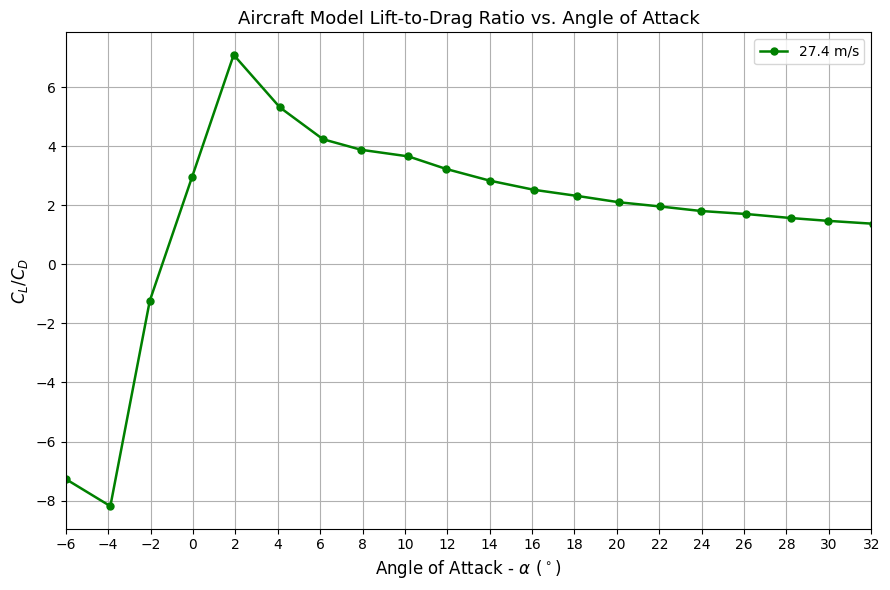

In [36]:
# lift/drag ratio
LD40 = CL40 / CD40
LD65 = CL65 / CD65
LD90 = CL90 / CD90

plt.figure(figsize=(9, 6))
plt.plot(alpha90, LD90,color='green',marker='o',linewidth=1.8,markersize=5,label='27.4 m/s')
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_L/C_D$', fontsize=12)
plt.title(r'Aircraft Model Lift-to-Drag Ratio vs. Angle of Attack', fontsize=13)
plt.xlim(-6, 32)
plt.xticks(np.arange(-6, 33, 2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

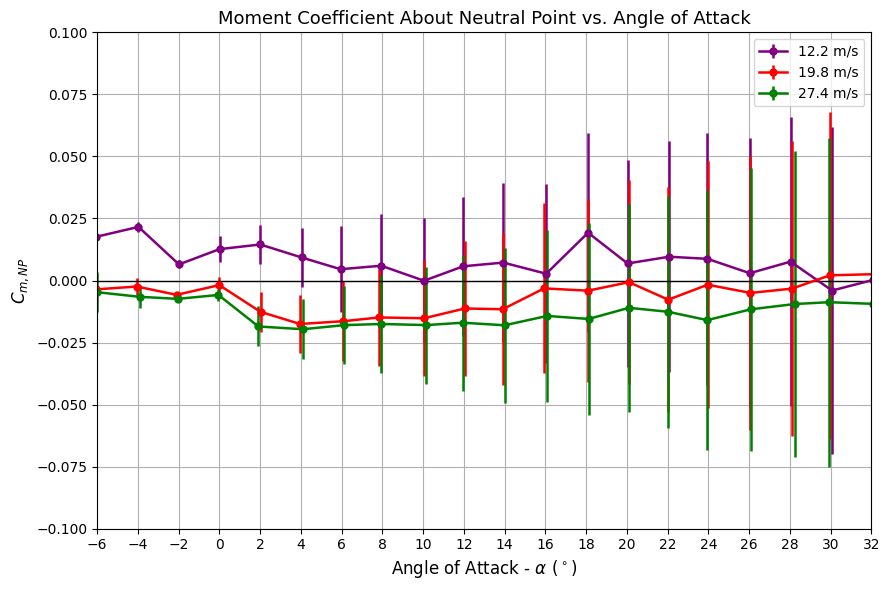

In [41]:
# neutral point + moment coefficient about neutral point
# model values
S_ft2 = 0.0819027778 #[ft^2]
MAC_m = 0.0934 #[m]
c_ft = MAC_m * 3.28084 #[ft]
c_in = 5.5  #[in]
x_balance_mm = 125.73 #[mm]

# Convert recorded pitching moments from in-lbf to ft-lbf
M40_ftlbf = M40 / 12
M65_ftlbf = M65 / 12
M90_ftlbf = M90 / 12

mask40 = (alpha40 >= 2) & (alpha40 <= 14)
mask65 = (alpha65 >= 2) & (alpha65 <= 14)
mask90 = (alpha90 >= 2) & (alpha90 <= 14)

x_np40 = np.polyfit(N40[mask40],M40_ftlbf[mask40],1)[0]
x_np65 = np.polyfit(N65[mask65],M65_ftlbf[mask65],1)[0]
x_np90 = np.polyfit(N90[mask90],M90_ftlbf[mask90],1)[0]

# average neutral point offset from balance center
x_np_avg = np.mean([x_np40, x_np65, x_np90])

# uncertainty in neutral point from spread of the three estimates
U_xnp = np.std([x_np40, x_np65, x_np90], ddof=1)   # [ft]

# convert to units
x_np40_in = x_np40 * 12
x_np65_in = x_np65 * 12
x_np90_in = x_np90 * 12
x_np_avg_in = x_np_avg * 12
x_np_avg_mm = x_np_avg * 304.8
x_np_from_nose_mm = x_balance_mm - x_np_avg_mm

M40_NP = M40_ftlbf - N40 * x_np_avg
M65_NP = M65_ftlbf - N65 * x_np_avg
M90_NP = M90_ftlbf - N90 * x_np_avg

# uncertainty
U_BAL = 0.05

U_N40 = U_BAL * np.abs(N40)
U_N65 = U_BAL * np.abs(N65)
U_N90 = U_BAL * np.abs(N90)
U_M40 = U_BAL * np.abs(M40_ftlbf)
U_M65 = U_BAL * np.abs(M65_ftlbf)
U_M90 = U_BAL * np.abs(M90_ftlbf)
Cm40_NP = M40_NP / (q40_psf * S_ft2 * c_ft)
Cm65_NP = M65_NP / (q65_psf * S_ft2 * c_ft)
Cm90_NP = M90_NP / (q90_psf * S_ft2 * c_ft)

# uncertainty in moment about neutral point
U_M40_NP = np.sqrt(U_M40**2 + (x_np_avg * U_N40)**2 + (N40 * U_xnp)**2)
U_M65_NP = np.sqrt(U_M65**2 + (x_np_avg * U_N65)**2 + (N65 * U_xnp)**2)
U_M90_NP = np.sqrt(U_M90**2 + (x_np_avg * U_N90)**2 + (N90 * U_xnp)**2)

# uncertainty in moment coefficient about neutral point
U_Cm40_NP = np.sqrt((U_M40_NP / (q40_psf * S_ft2 * c_ft))**2 + (M40_NP * U_q_psf / (q40_psf**2 * S_ft2 * c_ft))**2)
U_Cm65_NP = np.sqrt((U_M65_NP / (q65_psf * S_ft2 * c_ft))**2 + (M65_NP * U_q_psf / (q65_psf**2 * S_ft2 * c_ft))**2)
U_Cm90_NP = np.sqrt((U_M90_NP / (q90_psf * S_ft2 * c_ft))**2 + (M90_NP * U_q_psf / (q90_psf**2 * S_ft2 * c_ft))**2)

plt.figure(figsize=(9, 6))
plt.errorbar(alpha40, Cm40_NP, yerr=U_Cm40_NP, color='purple', marker='o', linewidth=1.8 ,markersize=5, label='12.2 m/s')
plt.errorbar(alpha65, Cm65_NP, yerr=U_Cm65_NP, color='red', marker='o', linewidth=1.8, markersize=5, label='19.8 m/s')
plt.errorbar(alpha90, Cm90_NP, yerr=U_Cm90_NP, color='green', marker='o', linewidth=1.8, markersize=5, label='27.4 m/s')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_{m,NP}$', fontsize=12)
plt.title(r'Moment Coefficient About Neutral Point vs. Angle of Attack',fontsize=13)
plt.xlim(-6, 32)
plt.xticks(np.arange(-6, 33, 2))
plt.ylim(-0.1,0.1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()